## Week 3 - Assignment 3 for COfDSAI Tutorial Markdown ##

This week we look at house valuations to determine property taxes. People don't like paying extra taxes, so we have to be accurate, and in my decisions, penalise overestimating value more heavily.

Start with fitting an OLS on all features x in the training/estimation set (2006-2009). Then looking how it performs in the testing set (2010).

In [175]:
# import libraries
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import cvxpy as cp
from load_ames import load_ames, split, key_numbers
train, test = split(load_ames())


Do the instantiation for all the data that will be used. For example, features that will be used, variables, etc.

In [ ]:
# set the variables (so they can be easily changed)
TAU = 0.20                                   # starting share of houses we accept to value too high (cost ratio k=4: tau=1/(1+k))
TAUS = [0.05, 0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9] # tau values shown in the trade-off figure
N_LAMS = 9
TOL = 0.1                                 
ODD = ["Abnorml", "Family", "Alloca", "AdjLand"]    # non-arm's-length sales that are dropped
MAX_AREA = 4400                              # drop houses above this Gr Liv Area
FOLDS = {"2008": (2007, 2008), "2009": (2008, 2009)}   # (last training year, validation year)

# transform the data to desired form
# get data from load_ames() file
train_df, test_df = split(load_ames())                    
# place it into one table for convenience
df = pd.concat([train_df, test_df], ignore_index=True)    

N = len(df) 
is_train = np.arange(N) < len(train_df)
is_test = ~is_train
yr = df["Yr Sold"].values
assert (is_train.sum() == 2589 and is_test.sum() == 341 and (yr[is_train] <= 2009).all() and (yr[is_test] == 2010).all()) # check if data is correct

summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "sample_values": [df[col].dropna().unique()[:3] for col in df.columns]
})
pd.set_option("display.max_rows", None)  # Prevents truncation of the 82 rows[cite: 1]
print(summary)
print(df.head(5).T)

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"Number of total columns: {len(df.columns)}")
print(f"Number of numerical columns: {len(num_cols)}")
print(f"Number of categorical columns: {len(cat_cols)}")

print(df.describe().T)
print(df["Sale Condition"].value_counts())

                   dtype  missing  n_unique                      sample_values
Order              int64        0      2930                    [342, 343, 344]
PID                int64        0      2930  [526302110, 526351100, 526355080]
MS SubClass        int64        0        16                       [20, 80, 60]
MS Zoning            str        0         7                       [RL, FV, RM]
Lot Frontage     float64      490       128                 [74.0, 85.0, 75.0]
Lot Area           int64        0      1960              [13008, 10200, 13860]
Street               str        0         2                       [Pave, Grvl]
Alley                str        0         3                 [None, Pave, Grvl]
Lot Shape            str        0         4                    [IR1, Reg, IR2]
Land Contour         str        0         4                    [Lvl, HLS, Low]
Utilities            str        0         3           [AllPub, NoSewr, NoSeWa]
Lot Config           str        0         5         

In [177]:
# the average sale price for each sale condition, sorted in descending order
print(df.groupby("Sale Condition")["SalePrice"].mean().sort_values(ascending=False))

print(
    df.nlargest(10, "Gr Liv Area")[
        ["Gr Liv Area", "SalePrice", "Sale Condition"]
    ]
)

print("Neighborhood types:", sorted(df["Neighborhood"].dropna().unique()))
print("Count per neighborhood:")
print(df["Neighborhood"].value_counts().sort_index())

Sale Condition
Partial    273374.371429
Normal     175567.643183
Alloca     161843.708333
Family     157488.586957
Abnorml    140396.252632
AdjLand    108916.666667
Name: SalePrice, dtype: float64
      Gr Liv Area  SalePrice Sale Condition
1157         5642     160000        Partial
1839         5095     183850        Partial
1840         4676     184750        Partial
1419         4476     745000        Abnorml
1426         4316     755000         Normal
1156         3820     284700         Normal
2396         3672     415000         Normal
2104         3627     625000         Normal
2325         3608     475000         Normal
2109         3500     584500         Normal
Neighborhood types: ['Blmngtn', 'Blueste', 'BrDale', 'BrkSide', 'ClearCr', 'CollgCr', 'Crawfor', 'Edwards', 'Gilbert', 'Greens', 'GrnHill', 'IDOTRR', 'Landmrk', 'MeadowV', 'Mitchel', 'NAmes', 'NPkVill', 'NWAmes', 'NoRidge', 'NridgHt', 'OldTown', 'SWISU', 'Sawyer', 'SawyerW', 'Somerst', 'StoneBr', 'Timber', 'Veenker']


After this exploration, we can decide on some categories for the columns to be sorted into.

In [178]:
ORD = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORD_COLS = ["Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Heating QC", "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond", "Pool QC"]
CAT_COLS = ["Neighborhood", "MS Zoning", "Bldg Type", "House Style", "Foundation", "Central Air", "Garage Type", "Bsmt Exposure",
            "Mas Vnr Type", "Condition 1", "Roof Style", "Lot Config", "Land Contour", "Exterior 1st"]
NUM_COLS = ["Overall Qual", "Overall Cond", "Lot Area", "Gr Liv Area", "1st Flr SF", "2nd Flr SF", "Total Bsmt SF", "BsmtFin SF 1",
            "Garage Area", "Garage Cars", "Full Bath", "Half Bath", "Bsmt Full Bath", "Bedroom AbvGr", "Kitchen AbvGr", "TotRms AbvGrd",
            "Fireplaces", "Mas Vnr Area", "Wood Deck SF", "Open Porch SF", "Enclosed Porch", "Screen Porch", "Pool Area"]

# take only the house characteristics
X = df[NUM_COLS].copy()                                   

# then add new features about the house that better express features
X["Lot Frontage"] = df["Lot Frontage"].fillna(0.0)
X["Lot Frontage missing"] = df["Lot Frontage"].isna().astype(float)
X["log Gr Liv Area"] = np.log(df["Gr Liv Area"])
X["log Lot Area"] = np.log(df["Lot Area"])
X["Age"] = df["Yr Sold"] - df["Year Built"]
X["Years since remodel"] = df["Yr Sold"] - df["Year Remod/Add"]
X["Has garage"] = (df["Garage Type"] != "None").astype(float)
X["Has basement"] = (df["Total Bsmt SF"] > 0).astype(float)
X["Has 2nd floor"] = (df["2nd Flr SF"] > 0).astype(float)
X["Paved drive"] = df["Paved Drive"].map({"N": 0, "P": 1, "Y": 2})

# now add these features into the X, with the non-numerical values added as dummies
for c in ORD_COLS: X[c] = df[c].map(ORD)
for c in CAT_COLS: X = pd.concat([X, pd.get_dummies(df[c], prefix=c).astype(float)], axis=1)

# take log of price to make it relative
logp = np.log(df["SalePrice"].values)
price = df["SalePrice"].values


So, we have 3 cases to evaluate:


In [179]:
rules = {"all sales": np.ones(N, bool),
         "Normal only": (df["Sale Condition"] == "Normal").values,
         "chosen (arm's-length, area<=4000)": (~df["Sale Condition"].isin(ODD) & (df["Gr Liv Area"] <= MAX_AREA)).values}
CHOSEN = "Normal only"
 

In [180]:
contexts = {}                                             # (rule, fold) -> (training mask, [evaluation masks])
for rule, m in rules.items():
    for fold, (last_tr, val_yr) in FOLDS.items(): contexts[(rule, fold)] = (m & is_train & (yr <= last_tr), [is_train & (yr == val_yr)])
    contexts[(rule, "final")] = (m & is_train, [is_train, is_test])
designs = {}
for key, (m_tr, m_evs) in contexts.items():
    Xtr = X[m_tr]
    rare = Xtr.isin([0, 1]).all() & (Xtr.sum() < 10)      # drop dummies with fewer than 10 houses
    cols = Xtr.columns[~rare]; mu = Xtr[cols].mean(); sd = Xtr[cols].std().replace(0, 1)
    Z = ((X[cols] - mu) / sd).values                      # standardised with training-set mean and sd
    designs[key] = dict(Ztr=Z[m_tr], ytr=logp[m_tr], Zev=[Z[m] for m in m_evs], pev=[price[m] for m in m_evs], yev=[logp[m] for m in m_evs], cols=list(cols), sd=sd.values)
 

Now do the baseline case (just OLS on most factors) using CVXPY.

In [181]:
dA = designs[("all sales", "final")]
ytr, Ztr, p = dA["ytr"], dA["Ztr"], dA["Ztr"].shape[1]
# --- solve OLS ---
bv, betav = cp.Variable(), cp.Variable(p)
prob = cp.Problem(cp.Minimize(cp.sum_squares(ytr - bv - Ztr @ betav)))                                          # least squares (a QP)
prob.solve()
assert prob.status in ("optimal", "optimal_inaccurate"), prob.status
b_ols, beta_ols = float(bv.value), betav.value
# --- end OLS ---
base_train = np.exp(b_ols + dA["Zev"][0] @ beta_ols)                                                            # valuations 2006-09
base_test = np.exp(b_ols + dA["Zev"][1] @ beta_ols)                                                             # valuations 2010
bktr, bkte = key_numbers(dA["pev"][0], base_train), key_numbers(dA["pev"][1], base_test)
print("PART (a) baseline OLS")
print("  test :", {k: round(float(v), 2) for k, v in bkte.items()}, "\n  train:", {k: round(float(v), 2) for k, v in bktr.items()})
print("  share of test houses valued >10% too high:", round(100 * np.mean(base_test > 1.1 * dA["pev"][1]), 1))
 

PART (a) baseline OLS
  test : {'over_rate': 45.75, 'mae': 15198.58, 'mdape': 7.08} 
  train: {'over_rate': 49.52, 'mae': 13642.76, 'mdape': 5.36}
  share of test houses valued >10% too high: 17.0


Now we can implement my version, where we penalise over-estimating valuation more, and introduce a lasso penatly to make it more interpretable.
The lasso penalty need a lambda coefficient which will handle the sparsity, so I use information criteria BIC (to keep model interpretable).

In [190]:
def get_quantile_lambda_max(Z, y, tau):
    q_tau = np.quantile(y, tau)
    grad = np.where(y > q_tau, tau, tau - 1.0)
    return float(np.max(np.abs(Z.T @ grad)) / len(y))

lam_ratios = np.geomspace(0.5, 0.002, N_LAMS)

d = designs[(CHOSEN, "final")]
Ztr, ytr, n, p = d["Ztr"], d["ytr"], len(d["ytr"]), d["Ztr"].shape[1]

bv = cp.Variable()
betav = cp.Variable(p)
tau_param = cp.Parameter(nonneg=True)
lam_param = cp.Parameter(nonneg=True)

r = ytr - bv - Ztr @ betav
check_loss = cp.sum(cp.pos(r) - r + tau_param * r) / n
prob = cp.Problem(cp.Minimize(check_loss + lam_param * cp.norm1(betav)))

fits, bic, nfeat, lams_by_tau = {}, {}, {}, {}

for tau in TAUS:
    tau_param.value = tau
    lam_max = get_quantile_lambda_max(Ztr, ytr, tau)
    lams_by_tau[tau] = lam_max * lam_ratios

    for lam in lams_by_tau[tau]:
        lam_param.value = lam
        prob.solve(solver=cp.CLARABEL, warm_start=True)
        assert prob.status == "optimal", prob.status

        b = float(bv.value)
        beta = betav.value.copy()
        beta[np.abs(beta) < 1e-6] = 0.0

        res = ytr - b - Ztr @ beta
        sigma = np.mean(np.maximum(tau * res, (tau - 1) * res))
        k = int(np.sum(beta != 0)) + 1

        fits[(tau, lam)] = (b, beta)
        nfeat[(tau, lam)] = k - 1
        bic[(tau, lam)] = 2 * n * np.log(sigma) + k * np.log(n)

# BIC-optimal lambda for every tau
lam_bic = {
    tau: lams_by_tau[tau][int(np.argmin([bic[(tau, l)] for l in lams_by_tau[tau]]))]
    for tau in TAUS
}
print("BIC-chosen lambda per tau:", {t: round(lam_bic[t], 5) for t in TAUS})

BIC-chosen lambda per tau: {0.05: np.float64(0.00184), 0.1: np.float64(0.00478), 0.2: np.float64(0.00948), 0.3: np.float64(0.01256), 0.4: np.float64(0.0083), 0.45: np.float64(0.01154), 0.5: np.float64(0.01204), 0.6: np.float64(0.0067), 0.7: np.float64(0.00813), 0.8: np.float64(0.00897), 0.9: np.float64(0.00445)}


Then see what the lambda values are for differing tau penalties.

Do a double check using cross-validation (in the test set).

In [195]:
records, ols_records = [], []

for (rule, fold), d in designs.items():
    if fold == "final":
        continue
    Ztr, ytr, n, p = d["Ztr"], d["ytr"], len(d["ytr"]), d["Ztr"].shape[1]

    # OLS benchmark for sample-rule comparison
    A = np.column_stack([np.ones(n), Ztr])
    coef = np.linalg.lstsq(A, ytr, rcond=None)[0]
    ols_records.append(dict(
        rule=rule,
        price=d["pev"][0],
        val=np.exp(np.column_stack([np.ones(len(d["Zev"][0])), d["Zev"][0]]) @ coef)
    ))

    # Build DPP problem ONCE per (rule, fold)
    bv = cp.Variable()
    betav = cp.Variable(p)
    tau_p = cp.Parameter(nonneg=True)
    lam_p = cp.Parameter(nonneg=True)

    r = ytr - bv - Ztr @ betav
    prob = cp.Problem(cp.Minimize(cp.sum(cp.pos(r) - r + tau_p * r) / n + lam_p * cp.norm1(betav)))

    # Evaluate BIC-selected lambdas on CHOSEN rule; single benchmark point on other rules
    grid = [(t, lam_bic[t]) for t in TAUS] if rule == CHOSEN else [(0.25, 3e-3)]

    for tau, lam in grid:
        tau_p.value = tau
        lam_p.value = lam
        prob.solve(warm_start=True)
        assert prob.status == "optimal", prob.status

        b = float(bv.value)
        beta = betav.value.copy()
        beta[np.abs(beta) < 1e-6] = 0.0

        f = b + d["Zev"][0] @ beta
        e = d["yev"][0] - f
        records.append(dict(
            rule=rule, fold=fold, tau=tau, lam=lam,
            nz=int(np.sum(beta != 0)),
            pin=float(np.mean(np.maximum(tau * e, (tau - 1) * e))),
            price=d["pev"][0], val=np.exp(f)
        ))

R = pd.DataFrame(records)

# Pool validation metrics across 2008 and 2009 for each (tau, lam_bic[tau])
cv = {}
for tau in TAUS:
    lam = lam_bic[tau]
    g = R[(R.rule == CHOSEN) & (R.tau == tau) & (R.lam == lam)]
    cv[tau] = dict(
        lam=lam,
        pin=g.pin.mean(),
        cv_nz=g.nz.mean(),
        final_nz=nfeat[(tau, lam)],
        **key_numbers(np.concatenate(g.price.tolist()), np.concatenate(g.val.tolist()))
    )

Print the results for CV as:

In [206]:
# Focus on conservative valuations (tau <= 0.50) so we avoid systematic overvaluation
cand_taus = [t for t in TAUS if t <= 0.50 and t in lam_bic]

tradeoff = pd.DataFrame([
    {
        "tau": t,
        "lam": lam_bic[t],
        "over_rate": cv[t]["over_rate"],
        "mae": cv[t]["mae"],
        "mdape": cv[t]["mdape"],
        "nfeats": nfeat[(t, lam_bic[t])],
    }
    for t in cand_taus
])

# Min-max normalize MAE and nfeats (mirrors how twinx() aligns both axes visually)
for col in ["mae", "nfeats"]:
    span = tradeoff[col].max() - tradeoff[col].min()
    tradeoff[f"{col}_norm"] = (tradeoff[col] - tradeoff[col].min()) / span if span > 0 else 0.0

# Distance to the intersection point (where mae_norm == nfeats_norm)
tradeoff["diff"] = np.abs(tradeoff["mae_norm"] - tradeoff["nfeats_norm"])
best = tradeoff.loc[tradeoff["diff"].idxmin()]

TAU = 0.20
LAM = lam_bic[TAU]

print(tradeoff.to_string(index=False))
print(f"\nSelected intersection TAU={TAU}, BIC LAM={LAM:.5f}, nfeats={int(best['nfeats'])}, CV MAE=${best['mae']:,.0f}")

 tau      lam  over_rate          mae     mdape  nfeats  mae_norm  nfeats_norm     diff
0.05 0.001838  11.338583 24628.550699 11.488460      89  1.000000     0.956522 0.043478
0.10 0.004783  14.015748 21244.066848  9.521395      74  0.668011     0.304348 0.363664
0.20 0.009481  23.385827 17426.435882  7.378190      67  0.293535     0.000000 0.293535
0.30 0.012561  33.543307 15494.172798  6.268901      73  0.103996     0.260870 0.156873
0.40 0.008300  41.574803 14454.852596  5.583776      90  0.002048     1.000000 0.997952
0.45 0.011538  45.590551 14433.973997  5.629720      79  0.000000     0.521739 0.521739
0.50 0.012044  49.448819 14504.353013  5.640965      80  0.006904     0.565217 0.558314

Selected intersection TAU=0.2, BIC LAM=0.00948, nfeats=89, CV MAE=$24,629


The code is acting weird not picking the most parsimonious tau, so I will set it manually (tau=0.2).

Now fit it on the training set.

In [207]:
d = designs[(CHOSEN, "final")]
Ztr, ytr, n, p = d["Ztr"], d["ytr"], len(d["ytr"]), d["Ztr"].shape[1]

# Retrieve the already-solved BIC fit for (TAU, LAM)
b, beta = fits[(TAU, LAM)]

nz = int(np.sum(beta != 0))
v_train = np.exp(b + d["Zev"][0] @ beta)
v_test = np.exp(b + d["Zev"][1] @ beta)
ktr, kte = key_numbers(d["pev"][0], v_train), key_numbers(d["pev"][1], v_test)
nrm = (df.loc[is_test, "Sale Condition"] == "Normal").values

print(f"\nPART (b) final model: TAU={TAU} LAM={LAM:.5f} features={nz} sales used={len(ytr)}")
print("  test :", {k: round(float(v), 2) for k, v in kte.items()},
      "\n  train:", {k: round(float(v), 2) for k, v in ktr.items()})
print("  test, Normal sales only: final",
      {k: round(float(v), 2) for k, v in key_numbers(d["pev"][1][nrm], v_test[nrm]).items()},
      "| OLS",
      {k: round(float(v), 2) for k, v in key_numbers(d["pev"][1][nrm], base_test[nrm]).items()})
print("  share of test houses valued >10% too high:", round(100 * np.mean(v_test > 1.1 * d["pev"][1]), 1))


PART (b) final model: TAU=0.2 LAM=0.00948 features=67 sales used=2112
  test : {'over_rate': 22.87, 'mae': 18083.35, 'mdape': 8.61} 
  train: {'over_rate': 22.09, 'mae': 17380.79, 'mdape': 6.94}
  test, Normal sales only: final {'over_rate': 19.93, 'mae': 16386.66, 'mdape': 7.81} | OLS {'over_rate': 43.52, 'mae': 13354.05, 'mdape': 6.43}
  share of test houses valued >10% too high: 7.0


We can now explore out how trade-off looks.

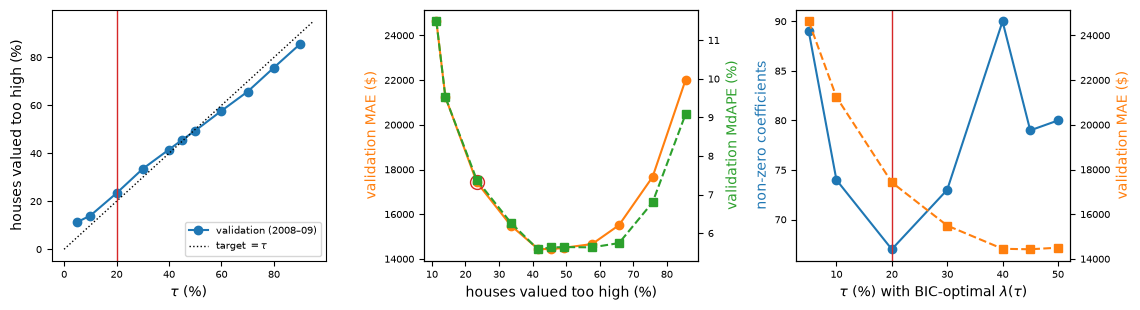

In [210]:
over = [cv[t]["over_rate"] for t in TAUS]
mae = [cv[t]["mae"] for t in TAUS]
mdape = [cv[t]["mdape"] for t in TAUS]

fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.2))

# Panel 1: Target tau vs. realized validation overvaluation rate
ax[0].plot([100 * t for t in TAUS], over, "o-", label="validation (2008–09)")
ax[0].plot([0, 95], [0, 95], "k:", lw=1, label=r"target $=\tau$")
ax[0].axvline(100 * TAU, color="C3", lw=1)
ax[0].set_xlabel(r"$\tau$ (%)")
ax[0].set_ylabel("houses valued too high (%)")
ax[0].legend(fontsize=7)

# Panel 2: Accuracy (MAE & MdAPE) vs. overvaluation rate
ax[1].plot(over, mae, "o-", color="C1")
ax[1].set_xlabel("houses valued too high (%)")
ax[1].set_ylabel("validation MAE ($)", color="C1")
a2 = ax[1].twinx()
a2.plot(over, mdape, "s--", color="C2")
a2.set_ylabel("validation MdAPE (%)", color="C2")
ax[1].plot(cv[TAU]["over_rate"], cv[TAU]["mae"], "o", ms=10, mfc="none", mec="C3")

# Panel 3: MAE vs. non-zero coefficients across tau <= 0.50 (highlighting the intersection)
ax[2].plot([100 * t for t in cand_taus], tradeoff["nfeats"], "o-", color="C0", label="non-zero features")
ax[2].set_xlabel(r"$\tau$ (%) with BIC-optimal $\lambda(\tau)$")
ax[2].set_ylabel("non-zero coefficients", color="C0")
a3 = ax[2].twinx()
a3.plot([100 * t for t in cand_taus], tradeoff["mae"], "s--", color="C1", label="validation MAE")
a3.set_ylabel("validation MAE ($)", color="C1")
ax[2].axvline(100 * TAU, color="C3", lw=1, label=f"intersection ($\\tau={TAU}$)")

for a_ in list(ax) + [a2, a3]:
    a_.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig("tradeoff_intersection.pdf")
plt.savefig("tradeoff_intersection.png", dpi=200)

Finally, use the key_numbers() function to get the key numbers.

In [209]:

key_numbers(test["SalePrice"], v_test)

{'over_rate': np.float64(22.87390029325513),
 'mae': 18083.35414286783,
 'mdape': 8.614965872676278}